In [33]:
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
import kagglehub
import os
import glob
import matplotlib.pyplot as plt
from keras.callbacks import ModelCheckpoint
from keras.layers import Dense, Flatten, Rescaling,BatchNormalization, Conv2D, MaxPooling2D,Dropout,Input, Activation
from keras.models import Sequential
from keras.callbacks import EarlyStopping
from keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.utils import set_random_seed


In [13]:
## download the data
path= kagglehub.dataset_download("jangedoo/utkface-new")
print(path)


Using Colab cache for faster access to the 'utkface-new' dataset.
/kaggle/input/utkface-new


In [14]:
#check
print(os.listdir(path))

['UTKFace', 'utkface_aligned_cropped', 'crop_part1']


In [16]:
#create data_dir for the data
DATA_DIR = path + "/UTKFace"
files = os.listdir(DATA_DIR)
print(files[:3])

['26_0_2_20170104023102422.jpg.chip.jpg', '22_1_1_20170112233644761.jpg.chip.jpg', '21_1_3_20170105003215901.jpg.chip.jpg']


In [6]:
!mkdir -p ~/.kaggle
!cp "/content/kaggle (3).json" ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json
!pip install -q kaggle

cp: cannot stat '/content/kaggle (3).json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


## read the data

In [17]:
!kaggle datasets download -d jangedoo/utkface-new -p /content/data --unzip

Dataset URL: https://www.kaggle.com/datasets/jangedoo/utkface-new
License(s): copyright-authors
100% 331M/331M [00:15<00:00, 21.8MB/s]



In [18]:
!ls /content/data

crop_part1  UTKFace  utkface_aligned_cropped


In [19]:
folder = '/content/data/UTKFace'
len(os.listdir(folder))

23708

In [20]:
path = '/content/data/UTKFace/'
image_paths = glob.glob(path + '*.jpg')
print(len(image_paths))
image_paths[0]

23708


'/content/data/UTKFace/40_0_0_20170116182430598.jpg.chip.jpg'

/content/data/UTKFace/40_0_0_20170116182430598.jpg.chip.jpg


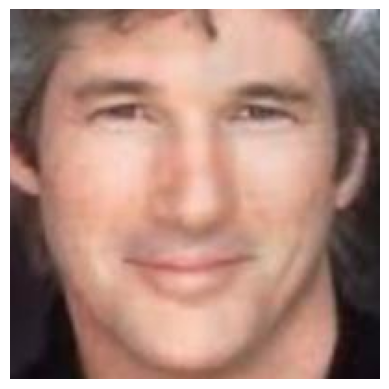

In [12]:
path = '/content/data/UTKFace/'
image_paths = glob.glob(path + '*.jpg')

print(image_paths[0])
plt.imshow(Image.open(image_paths[0]))
plt.axis("off")
plt.show()

In [22]:
#data loadind and preprocessing

In [21]:
x= []
y= []

for f in files:
    img = tf.keras.utils.load_img(DATA_DIR + "/" + f, target_size=(64, 64))
    x.append(np.array(img) / 255.0)
    y.append(int(f.split("_")[0]))

x= np.array(x)
y= np.array(y)

In [23]:
print(x.shape, y.shape)

(23708, 64, 64, 3) (23708,)


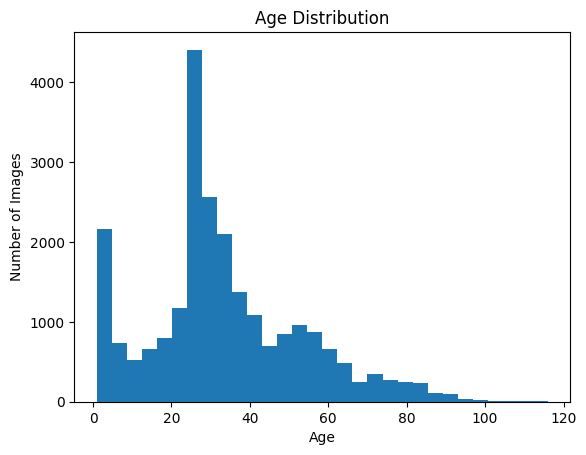

In [24]:
#the distribution of the data
plt.hist(y, bins=30)
plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Images")
plt.show()

In [25]:
#image dimensions, color channels
print(x[0].shape)

(64, 64, 3)


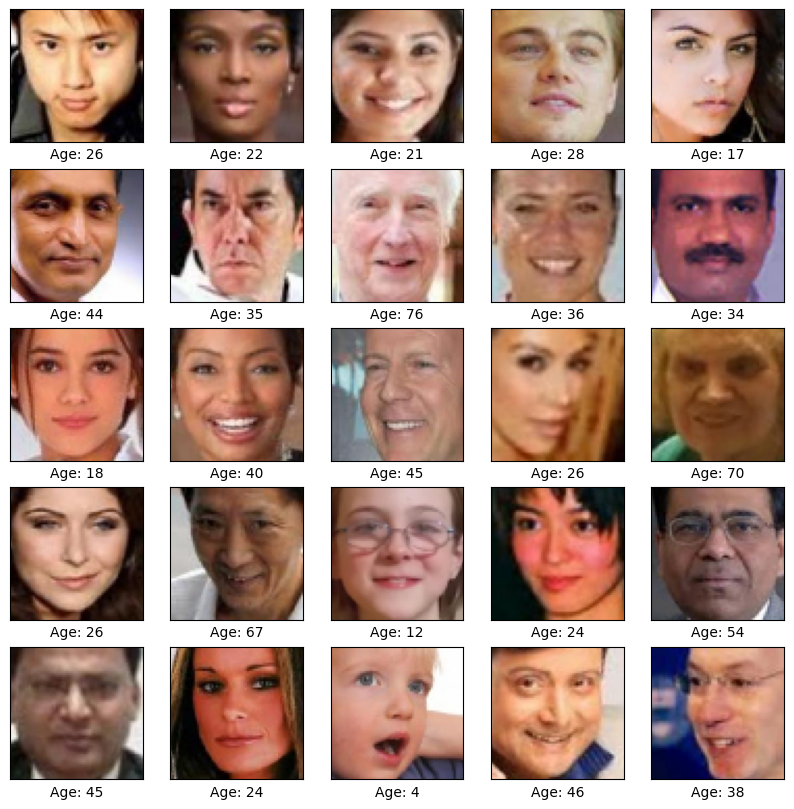

In [26]:
# sample of the images
plt.figure(figsize=(10, 10))

for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(x[i])
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel(f"Age: {int(y[i])}")

plt.show()

In [27]:
# split the data to train , validation , test
x_train_val, x_test, y_train_val, y_test= train_test_split(x, y, test_size=0.15, random_state=42)
x_train, x_val, y_train, y_val = train_test_split(x_train_val, y_train_val, test_size=0.15, random_state=42)

In [28]:
print(x_train.shape, x_val.shape, x_test.shape)

(17128, 64, 64, 3) (3023, 64, 64, 3) (3557, 64, 64, 3)


In [29]:
y_train[0:10]

array([26, 32, 26,  1, 29, 27, 80, 30, 59, 26])

## CNN  model

In [30]:
# early stoping step , to avoid the overfitting
early_stoping=EarlyStopping(monitor='val_loss',patience=3,restore_best_weights=True)

In [31]:
checkpoint_filepath = '/tmp/ckpt/checkpoint.model.keras'

model_checkpoint_callback = ModelCheckpoint(
    filepath=checkpoint_filepath,
    monitor='val_loss',
    mode='min',
    save_best_only=True)

In [34]:
#the Architecture of the cnn model
set_random_seed(42)

cnn_model = Sequential([
                    Input(shape=(64, 64, 3)),
                    Conv2D(20, (3, 3),activation="relu"),
                    MaxPooling2D((2, 2)),

                    Conv2D(30, (3, 3),activation="relu"),
                    MaxPooling2D((2, 2)),

                    Conv2D(40, (3, 3), activation="relu"),

                    Flatten(), # converting 2D -> 1D

                    Dense(100, activation='relu'), # Hidden layer 1

                    Dense(100, activation='relu'), # Hidden layer 2

                    Dense(100, activation='relu'), # Hidden layer 3

                    Dense(1)
                    ])

In [35]:
cnn_model.compile(optimizer="adam", loss="mae", metrics=["mae"])

In [36]:
cnn_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 20)     │           560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 20)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 30)     │         5,430 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 30)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 40)     │        10,840 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 5760)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       576,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 100)            │        10,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 613,231 (2.34 MB)

 Trainable params: 613,231 (2.34 MB)

 Non-trainable params: 0 (0.00 B)

In [37]:
histor= cnn_model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30,callbacks=[early_stoping, model_checkpoint_callback])

Epoch 1/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 76s 138ms/step - loss: 14.6828 - mae: 14.6828 - val_loss: 12.6617 - val_mae: 12.6617
Epoch 2/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 81s 136ms/step - loss: 10.5264 - mae: 10.5264 - val_loss: 9.3187 - val_mae: 9.3187
Epoch 3/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 72s 134ms/step - loss: 8.5855 - mae: 8.5855 - val_loss: 8.2581 - val_mae: 8.2581
Epoch 4/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 72s 135ms/step - loss: 7.8859 - mae: 7.8859 - val_loss: 7.9076 - val_mae: 7.9076
Epoch 5/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 73s 136ms/step - loss: 7.5721 - mae: 7.5721 - val_loss: 7.4913 - val_mae: 7.4913
Epoch 6/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 73s 136ms/step - loss: 7.1596 - mae: 7.1596 - val_loss: 7.4527 - val_mae: 7.4527
Epoch 7/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 81s 134ms/step - loss: 6.7899 - mae: 6.7899 - val_loss: 7.1099 - val_mae: 7.1099
Epoch 8/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 71s 133ms/step - loss: 6.6084 - mae: 6.6084 - val_loss: 6.9263 - val_mae: 6.9263
Epoch 9/30
536/536 ━━━━━━━

In [32]:
histor= cnn_model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30,callbacks=[early_stoping, model_checkpoint_callback])

Epoch 1/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 91s 169ms/step - loss: 5.7637 - mae: 5.7637 - val_loss: 6.7575 - val_mae: 6.7575
Epoch 2/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 126s 139ms/step - loss: 5.5752 - mae: 5.5752 - val_loss: 7.9377 - val_mae: 7.9377
Epoch 3/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 75s 140ms/step - loss: 5.4266 - mae: 5.4266 - val_loss: 6.9473 - val_mae: 6.9473
Epoch 4/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 77s 143ms/step - loss: 5.3408 - mae: 5.3408 - val_loss: 6.6234 - val_mae: 6.6234
Epoch 5/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 80s 138ms/step - loss: 5.0886 - mae: 5.0886 - val_loss: 6.9391 - val_mae: 6.9391
Epoch 6/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 76s 142ms/step - loss: 4.9755 - mae: 4.9755 - val_loss: 7.1514 - val_mae: 7.1514
Epoch 7/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 74s 139ms/step - loss: 4.7882 - mae: 4.7882 - val_loss: 7.1204 - val_mae: 7.1204


In [38]:
hist=pd.DataFrame(histor.history)

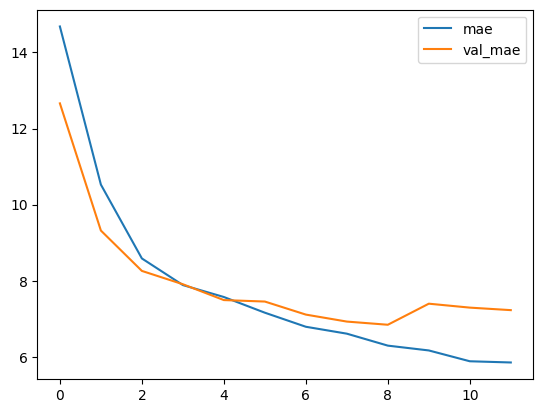

In [39]:
hist[["mae", "val_mae"]].plot();

In [45]:
test_loss, test_mae= cnn_model.evaluate(x_test, y_test)

112/112 ━━━━━━━━━━━━━━━━━━━━ 6s 57ms/step - loss: 6.6985 - mae: 6.6985


In [41]:
# error analysis:

In [44]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [46]:
y_pred = cnn_model.predict(x_test, verbose=0).flatten()

mae= mean_absolute_error(y_test, y_pred)
mse= mean_squared_error(y_test, y_pred)
rmse= np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Test MAE:", round(mae, 2))
print("Test MSE:", round(mse, 2))
print("Test RMSE:", round(rmse, 2))
print("Test R2 Score:", round(r2, 4))

Test MAE: 6.7
Test MSE: 93.04
Test RMSE: 9.65
Test R2 Score: 0.7618


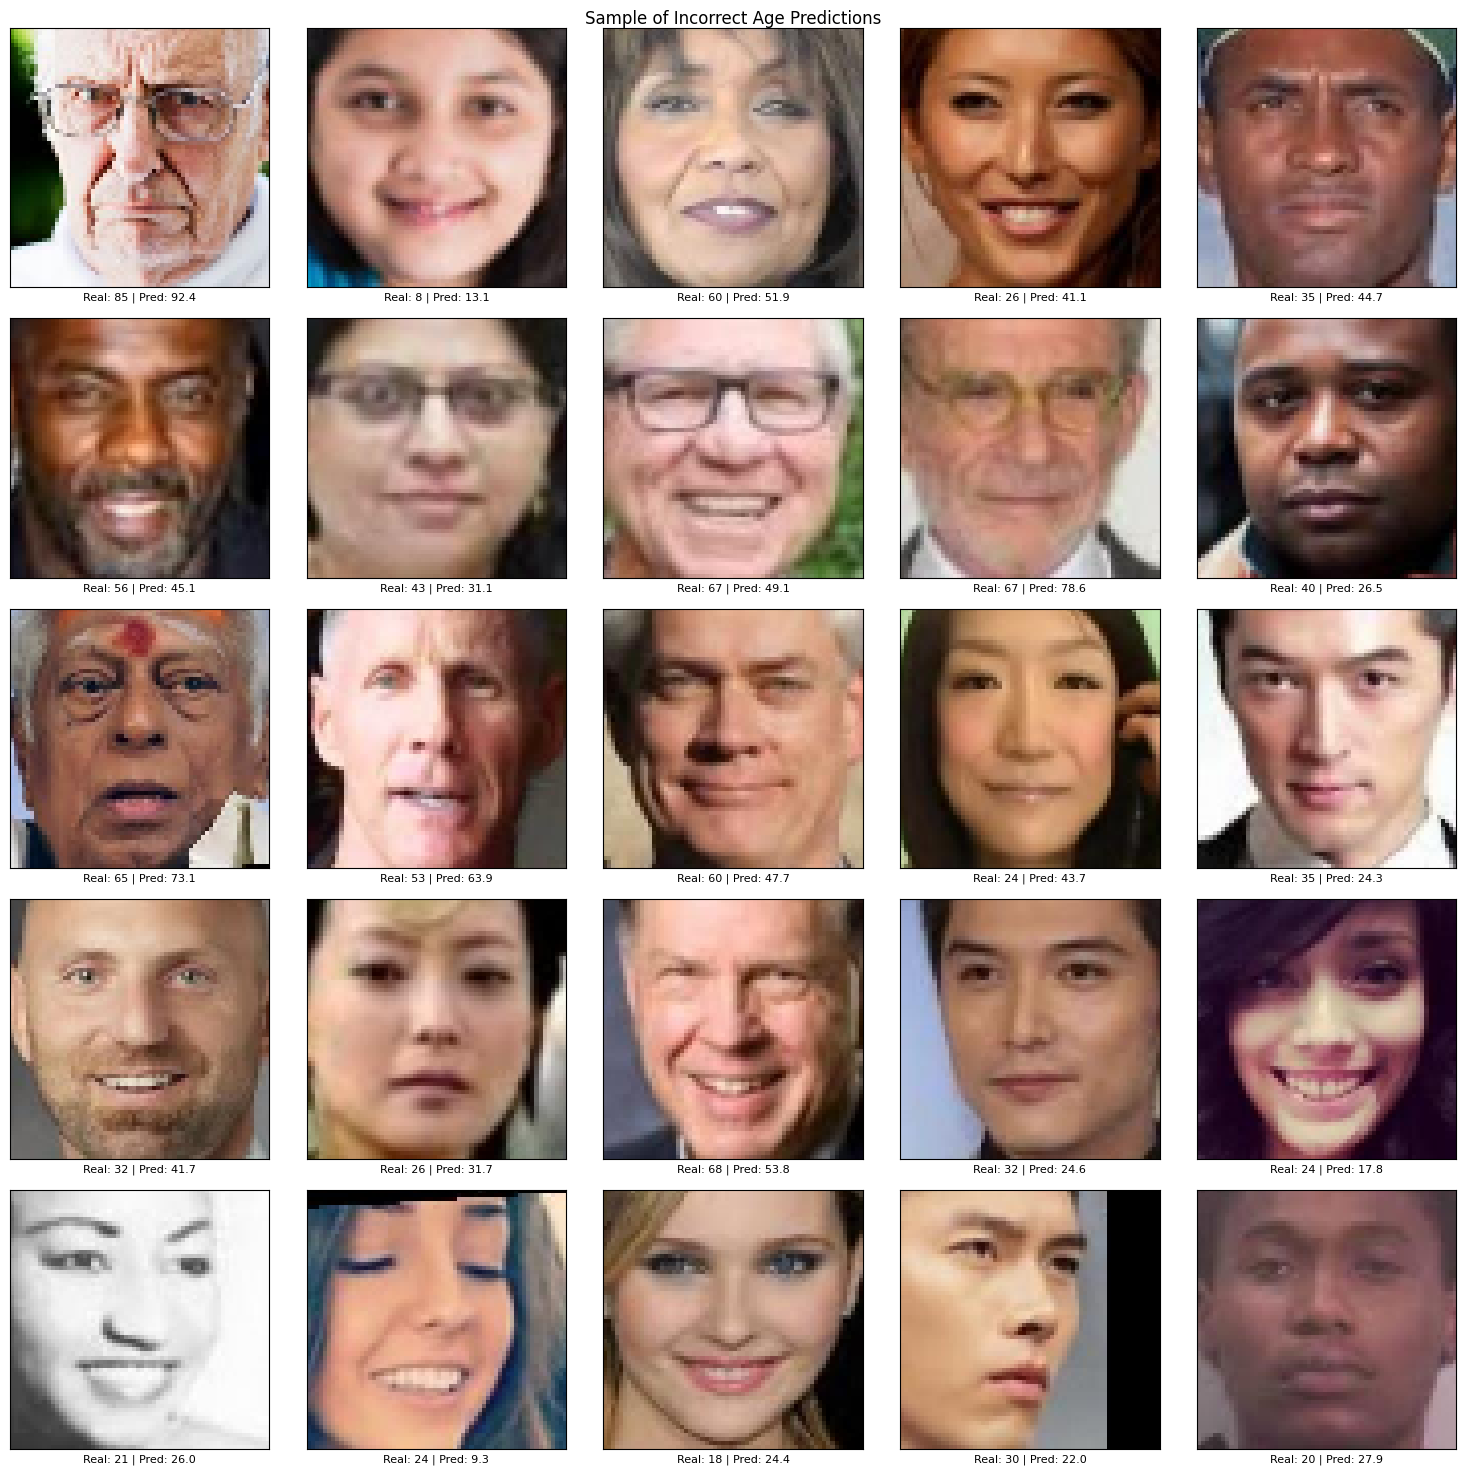

In [47]:
# sample of the images that had error more than 5 years:

all_preds= cnn_model.predict(x_test, verbose=0).flatten()
errors=np.abs(y_test- all_preds)
wrong=np.where(errors > 5)[0]

plt.figure(figsize=(15, 15))

for i in range(min(25, len(wrong))):
    idx = wrong[i]

    plt.subplot(5, 5, i + 1)
    plt.imshow(x_test[idx])
    plt.xticks([])
    plt.yticks([])

    plt.xlabel(
        f"Real: {y_test[idx]} | Pred: {all_preds[idx]:.1f}",
        fontsize=8
    )

plt.suptitle("Sample of Incorrect Age Predictions")
plt.tight_layout()
plt.show()

In [49]:
## improved model , adding the learning rate 0.0001

In [50]:
cnn_model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),loss="mae",metrics=["mae"])

In [51]:
history= cnn_model.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30,callbacks=[early_stoping,model_checkpoint_callback])

Epoch 1/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 81s 147ms/step - loss: 5.5721 - mae: 5.5721 - val_loss: 6.5578 - val_mae: 6.5578
Epoch 2/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 74s 133ms/step - loss: 5.4297 - mae: 5.4297 - val_loss: 6.5322 - val_mae: 6.5322
Epoch 3/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 71s 133ms/step - loss: 5.3399 - mae: 5.3399 - val_loss: 6.4990 - val_mae: 6.4990
Epoch 4/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 83s 136ms/step - loss: 5.2672 - mae: 5.2672 - val_loss: 6.4768 - val_mae: 6.4768
Epoch 5/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 74s 137ms/step - loss: 5.2038 - mae: 5.2038 - val_loss: 6.4450 - val_mae: 6.4450
Epoch 6/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 72s 133ms/step - loss: 5.1478 - mae: 5.1478 - val_loss: 6.4427 - val_mae: 6.4427
Epoch 7/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 73s 136ms/step - loss: 5.0801 - mae: 5.0801 - val_loss: 6.4193 - val_mae: 6.4193
Epoch 8/30
536/536 ━━━━━━━━━━━━━━━━━━━━ 82s 135ms/step - loss: 5.0254 - mae: 5.0254 - val_loss: 6.3902 - val_mae: 6.3902
Epoch 9/30
536/536 ━━━━━━━━━━━━━

In [52]:
history=pd.DataFrame(history.history)

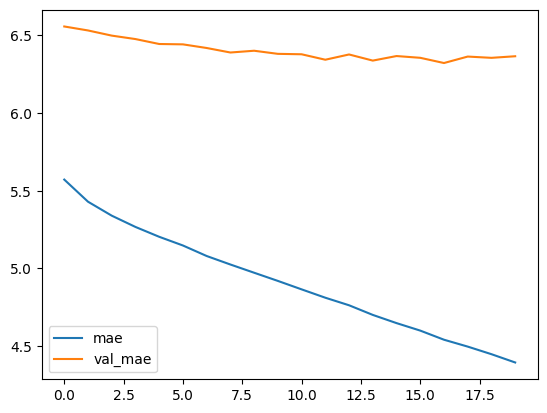

In [53]:
history[["mae", "val_mae"]].plot();

In [54]:
y_pred=cnn_model.predict(x_test, verbose=0).flatten()


In [55]:
mae=mean_absolute_error(y_test, y_pred)
mse=mean_squared_error(y_test, y_pred)
rmse=np.sqrt(mse)
r2=r2_score(y_test, y_pred)

print("Test MAE:", mae)
print("Test MSE:", mse)
print("Test RMSE:", rmse)
print("R² Score:", r2)

Test MAE: 6.137653827667236
Test MSE: 80.8370132446289
Test RMSE: 8.99094062068196
R² Score: 0.7930431365966797


In [ ]:
# save the model

In [56]:
cnn_model.save("age_prediction_model.keras")

#  gradio


In [60]:
from google.colab import files
files.download("age_prediction_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
import gradio as gr
from keras.models import load_model


In [58]:
def predict_age(image):
    image = tf.image.resize(image, (64, 64))
    image = np.array(image, dtype=np.float32) / 255.0
    image = np.expand_dims(image, axis=0)

    prediction = cnn_model.predict(image, verbose=0)[0][0]

    return f"Predicted Age: {prediction:.0f} years"

In [59]:
demo = gr.Interface(
    fn=predict_age,
    inputs=gr.Image(type="numpy", image_mode="RGB",sources=["upload", "webcam"]),
    outputs=gr.Textbox(label="Predicted Age"),
    title="Age Prediction from Facial Images",
    description="-"
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://541b8a8359c92e4561.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://541b8a8359c92e4561.gradio.live
